# 03 · Exploración e hipótesis

**Etapa 4.** Objetivo: responder H1 a H5 con los datos de PISA 2025 de Argentina, teniendo en cuenta el diseño de la muestra de la encuesta.

Cada resultado se resume con una de estas frases: *evidencia compatible con una asociación*, *evidencia insuficiente* o *no evaluable con estos datos*. Estudiamos **asociaciones**: nada de lo que sigue demuestra que la IA cause algo.

In [1]:
from pathlib import Path
from math import erfc, sqrt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raiz = Path.cwd()
while not (raiz / "README.md").exists():
    if raiz == raiz.parent:
        raise FileNotFoundError("No se encontró README.md: ejecutá el notebook dentro del proyecto.")
    raiz = raiz.parent

archivo = raiz / "data" / "processed" / "argentina_pisa2025_analitico.csv"
carpeta_figuras = raiz / "reports" / "figures"
carpeta_tablas = raiz / "reports" / "tables"

datos = pd.read_csv(archivo)
print("Estudiantes de Argentina:", len(datos))

Estudiantes de Argentina: 11092


## 1. Cómo se calculan los errores estándar

PISA no es una muestra simple: tiene escuelas y estudiantes elegidos con probabilidades distintas, y el rendimiento viene en **10 valores plausibles** por área. Por eso:

1. Cada estadístico (una media, una diferencia o un coeficiente) se calcula con el peso final `W_FSTUWT`, una vez por cada valor plausible, y se promedian los 10 resultados.
2. La variabilidad por el muestreo se calcula repitiendo el cálculo con cada uno de los 80 pesos replicados: `varianza = suma de (estimación con réplica − estimación con peso final)² / 20`. El divisor 20 sale de 80 réplicas con factor de Fay 0,5 (**supuesto que falta confirmar en la documentación técnica de PISA 2025**).
3. La variabilidad entre valores plausibles se suma con la regla de Rubin: `varianza total = varianza muestral + (1 + 1/10) × varianza entre valores plausibles`.
4. Cuando la variable no es un valor plausible (por ejemplo, el uso de IA) hay un solo cálculo y no se agrega el paso 3.

Los p-valores usan la distribución normal.

In [2]:
N_REPLICAS = 80
FACTOR_FAY = 0.5
DIVISOR = N_REPLICAS * (1 - FACTOR_FAY) ** 2     # 80 * 0.25 = 20

pesos_replicados = []
for i in range(1, 81):
    pesos_replicados.append("W_FSTURWT" + str(i))

pv_ciencias = []
pv_matematica = []
pv_lectura = []
for i in range(1, 11):
    pv_ciencias.append("PV" + str(i) + "SCIE")
    pv_matematica.append("PV" + str(i) + "MATH")
    pv_lectura.append("PV" + str(i) + "READ")

print("Divisor de la fórmula:", DIVISOR)

Divisor de la fórmula: 20.0


### Funciones estadísticas

Cada una recibe los datos, el valor plausible (o `None` si la variable no es un puntaje), el nombre de la columna de pesos y devuelve un arreglo con la estimación.

In [3]:
def media_pv(datos, pv, peso):
    media = np.average(datos[pv].values, weights=datos[peso].values)
    return np.array([media])


def media_variable(datos, pv, peso, variable):
    # pv no se usa acá: se deja para que todas las funciones reciban los mismos argumentos
    media = np.average(datos[variable].values, weights=datos[peso].values)
    return np.array([media])


def diferencia_pv(datos, pv, peso, columna, grupo_a, grupo_b):
    a = datos[datos[columna] == grupo_a]
    b = datos[datos[columna] == grupo_b]
    media_a = np.average(a[pv].values, weights=a[peso].values)
    media_b = np.average(b[pv].values, weights=b[peso].values)
    return np.array([media_a - media_b])


def diferencia_variable(datos, pv, peso, columna, grupo_a, grupo_b, variable):
    # pv no se usa acá, igual que en media_variable
    a = datos[datos[columna] == grupo_a]
    b = datos[datos[columna] == grupo_b]
    media_a = np.average(a[variable].values, weights=a[peso].values)
    media_b = np.average(b[variable].values, weights=b[peso].values)
    return np.array([media_a - media_b])


def regresion_pv(datos, pv, peso, predictores):
    y = datos[pv].values
    w = datos[peso].values
    columnas = [np.ones(len(datos))]
    for predictor in predictores:
        columnas.append(datos[predictor].values)
    X = np.column_stack(columnas)
    raiz_w = np.sqrt(w)
    coeficientes = np.linalg.lstsq(X * raiz_w[:, None], y * raiz_w, rcond=None)[0]
    return coeficientes

In [4]:
def estimar(datos, funcion, pvs, **argumentos):
    estimaciones = []
    varianzas = []

    for pv in pvs:
        estimacion = funcion(datos, pv, "W_FSTUWT", **argumentos)

        replicas = []
        for peso_replicado in pesos_replicados:
            replicas.append(funcion(datos, pv, peso_replicado, **argumentos))
        replicas = np.array(replicas)

        varianza_muestral = np.sum((replicas - estimacion) ** 2, axis=0) / DIVISOR
        estimaciones.append(estimacion)
        varianzas.append(varianza_muestral)

    estimaciones = np.array(estimaciones)
    varianzas = np.array(varianzas)
    m = len(pvs)

    estimacion_final = estimaciones.mean(axis=0)
    varianza_muestral = varianzas.mean(axis=0)
    if m > 1:
        varianza_entre_pv = estimaciones.var(axis=0, ddof=1)
    else:
        varianza_entre_pv = 0

    varianza_total = varianza_muestral + (1 + 1 / m) * varianza_entre_pv
    return estimacion_final, np.sqrt(varianza_total)

### Prueba de las funciones

Se comprueba que el error estándar con réplicas sea razonable comparándolo con el de una muestra simple al azar. Con una muestra por conglomerados (escuelas) el error con réplicas suele ser mayor.

In [5]:
muestra_escs = datos[datos["ESCS"].notna()].copy()

media, error = estimar(muestra_escs, media_variable, [None], variable="ESCS")
error_simple = muestra_escs["ESCS"].std() / np.sqrt(len(muestra_escs))

print("Media ponderada de ESCS:", round(media[0], 3))
print("Error estándar con réplicas:", round(error[0], 4))
print("Error estándar si fuera muestra simple:", round(error_simple, 4))
print("Cociente:", round(error[0] / error_simple, 2))

Media ponderada de ESCS: -0.632
Error estándar con réplicas: 0.0293
Error estándar si fuera muestra simple: 0.0106
Cociente: 2.77


## 2. Preparación de las muestras y cómo se leen los resultados

- **Muestra de ESCS** (H1): estudiantes con ESCS válido.
- **Muestra de IA** (H2 a H5): estudiantes con ESCS válido y las cuatro preguntas de IA contestadas.

Cada resultado se guarda en una tabla con la estimación, el error estándar, el intervalo de confianza del 95 %, el p-valor y el veredicto. El veredicto es *compatible con una asociación* solo si el intervalo no incluye el 0 y p < 0,05; si no, es *evidencia insuficiente* (que **no** equivale a demostrar que no hay asociación).

In [6]:
muestra_ia = muestra_escs[muestra_escs["ia_estado"] == "respondio_las_4"].copy()
print("Muestra de ESCS:", len(muestra_escs))
print("Muestra de IA:", len(muestra_ia))

# Variables centradas (para interpretar bien la interacción)
muestra_ia["escs_centrado"] = muestra_ia["ESCS"] - muestra_ia["ESCS"].mean()
muestra_ia["ia_centrado"] = muestra_ia["ia_promedio"] - muestra_ia["ia_promedio"].mean()
muestra_ia["ia_por_escs"] = muestra_ia["ia_centrado"] * muestra_ia["escs_centrado"]

actividades = {
    "ST438Q01DA": "Resumir un texto",
    "ST438Q02DA": "Investigar un tema",
    "ST438Q03DA": "Redactar borradores",
    "ST438Q04DA": "Ayudar a aprender",
}
for pregunta in actividades:
    muestra_ia["seguido_" + pregunta] = (muestra_ia[pregunta + "_grupo"] == "seguido").astype(int)

Muestra de ESCS: 9808
Muestra de IA: 7191


In [7]:
resultados = []

def guardar(hipotesis, parametro, n, estimacion, error, nota=""):
    z = estimacion / error
    p = erfc(abs(z) / sqrt(2))
    if p < 0.0001:
        texto_p = "<0,0001"
    else:
        texto_p = str(round(p, 4))
    inferior = estimacion - 1.96 * error
    superior = estimacion + 1.96 * error
    if p < 0.05 and (inferior > 0 or superior < 0):
        veredicto = "compatible con una asociación"
    else:
        veredicto = "evidencia insuficiente"
    resultados.append({
        "hipotesis": hipotesis, "parametro": parametro, "n": n,
        "estimacion": round(estimacion, 3), "error_estandar": round(error, 3),
        "ic95_inferior": round(inferior, 3), "ic95_superior": round(superior, 3),
        "p": p, "p_texto": texto_p, "veredicto": veredicto, "nota": nota,
    })

## 3. H1 · ESCS y rendimiento

**H0:** no hay asociación entre ESCS y rendimiento. Parámetros: pendiente de ESCS sobre el puntaje (puntos por cada unidad de ESCS) y diferencia entre el cuartil 4 y el cuartil 1 de ESCS.

In [8]:
areas = [("Ciencias", pv_ciencias), ("Matemática", pv_matematica), ("Lectura", pv_lectura)]

for nombre, pvs in areas:
    coeficientes, errores = estimar(muestra_escs, regresion_pv, pvs, predictores=["ESCS"])
    guardar("H1", "Pendiente de ESCS en " + nombre + " (puntos por unidad de ESCS)",
            len(muestra_escs), coeficientes[1], errores[1])

estimacion, error = estimar(muestra_escs, diferencia_pv, pv_ciencias,
                            columna="cuartil_escs", grupo_a=4.0, grupo_b=1.0)
guardar("H1", "Ciencias: cuartil 4 de ESCS menos cuartil 1 (puntos)", len(muestra_escs), estimacion[0], error[0])

tabla_h1 = pd.DataFrame(resultados)
print(tabla_h1[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]].to_string())

                                                     parametro     n  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto                      veredicto
0    Pendiente de ESCS en Ciencias (puntos por unidad de ESCS)  9808      30.585           2.169         26.334         34.836  <0,0001  compatible con una asociación
1  Pendiente de ESCS en Matemática (puntos por unidad de ESCS)  9808      29.290           1.978         25.414         33.166  <0,0001  compatible con una asociación
2     Pendiente de ESCS en Lectura (puntos por unidad de ESCS)  9808      28.180           2.030         24.201         32.159  <0,0001  compatible con una asociación
3         Ciencias: cuartil 4 de ESCS menos cuartil 1 (puntos)  9808      82.373           6.197         70.226         94.520  <0,0001  compatible con una asociación


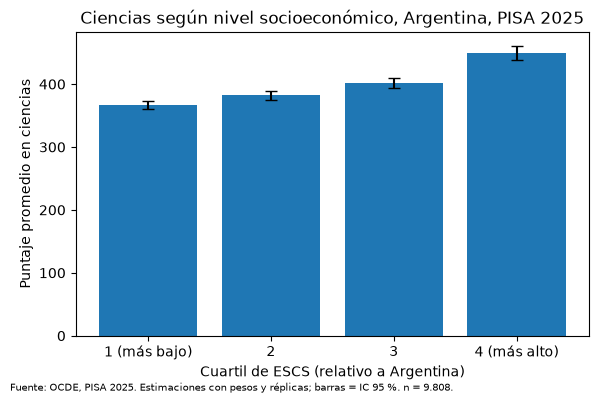

[366.6, 382.4, 401.9, 449.0]


In [9]:
# Figura: puntaje de ciencias promedio por cuartil de ESCS
medias = []
errores = []
for cuartil in [1.0, 2.0, 3.0, 4.0]:
    grupo = muestra_escs[muestra_escs["cuartil_escs"] == cuartil]
    media, error = estimar(grupo, media_pv, pv_ciencias)
    medias.append(media[0])
    errores.append(error[0])

fig, eje = plt.subplots(figsize=(6, 4))
intervalos = []
for e in errores:
    intervalos.append(1.96 * e)
eje.bar([1, 2, 3, 4], medias, yerr=intervalos, capsize=4)
eje.set_xticks([1, 2, 3, 4])
eje.set_xticklabels(["1 (más bajo)", "2", "3", "4 (más alto)"])
eje.set_xlabel("Cuartil de ESCS (relativo a Argentina)")
eje.set_ylabel("Puntaje promedio en ciencias")
eje.set_title("Ciencias según nivel socioeconómico, Argentina, PISA 2025")
fig.text(0.01, 0.01, "Fuente: OCDE, PISA 2025. Estimaciones con pesos y réplicas; barras = IC 95 %. n = 9.808.", fontsize=7)
fig.tight_layout()
fig.savefig(carpeta_figuras / "03_ciencias_por_cuartil_escs.png", dpi=120)
plt.show()
redondeadas = []
for m in medias:
    redondeadas.append(round(float(m), 1))
print(redondeadas)

**Lectura de H1.** Hay una asociación clara y grande entre ESCS y rendimiento. Por cada unidad más de ESCS, el puntaje en ciencias es en promedio 30,6 puntos más alto (IC 95 %: 26,3 a 34,8); en matemática 29,3 y en lectura 28,2. El cuartil más alto de ESCS supera al más bajo en 82,4 puntos de ciencias (IC 95 %: 70,2 a 94,5). Los promedios estimados por cuartil son 367, 382, 402 y 449 puntos. Este análisis usa los 9.808 estudiantes con ESCS válido (se pierde el 11,6 % sin ESCS). **Veredicto: evidencia compatible con una asociación.** Es una asociación; no indica por sí sola qué la causa.

## 4. H2 · Uso de IA y ESCS

**H0:** la frecuencia de uso de IA es independiente del ESCS. Parámetros: diferencia del promedio de las cuatro preguntas (escala 1 a 5) entre el cuartil 4 y el cuartil 1, y diferencia en el porcentaje que usa IA *seguido* (una vez por semana o más) en cada actividad. Solo con quienes respondieron.

In [10]:
estimacion, error = estimar(muestra_ia, diferencia_variable, [None],
                            columna="cuartil_escs", grupo_a=4.0, grupo_b=1.0, variable="ia_promedio")
guardar("H2", "Promedio de frecuencia de IA (1 a 5): cuartil 4 menos cuartil 1", len(muestra_ia), estimacion[0], error[0])

for pregunta in actividades:
    estimacion, error = estimar(muestra_ia, diferencia_variable, [None],
                                columna="cuartil_escs", grupo_a=4.0, grupo_b=1.0, variable="seguido_" + pregunta)
    guardar("H2", actividades[pregunta] + ": diferencia en la proporción que usa IA seguido, cuartil 4 menos cuartil 1 (0,10 = 10 puntos porcentuales)",
            len(muestra_ia), estimacion[0], error[0])

tabla_h2 = pd.DataFrame(resultados)
tabla_h2 = tabla_h2[tabla_h2["hipotesis"] == "H2"]
print(tabla_h2[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]].to_string())

                                                                                                                        parametro     n  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto                      veredicto
4                                                                 Promedio de frecuencia de IA (1 a 5): cuartil 4 menos cuartil 1  7191       0.490           0.067          0.358          0.621  <0,0001  compatible con una asociación
5     Resumir un texto: diferencia en la proporción que usa IA seguido, cuartil 4 menos cuartil 1 (0,10 = 10 puntos porcentuales)  7191       0.158           0.024          0.111          0.206  <0,0001  compatible con una asociación
6   Investigar un tema: diferencia en la proporción que usa IA seguido, cuartil 4 menos cuartil 1 (0,10 = 10 puntos porcentuales)  7191       0.169           0.026          0.117          0.221  <0,0001  compatible con una asociación
7  Redactar borradores: diferencia en la proporción que usa IA s

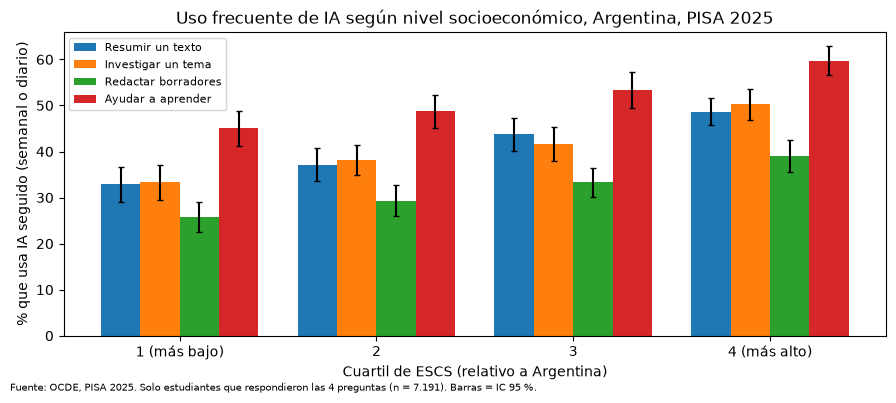

In [11]:
# Figura: porcentaje que usa IA seguido, por cuartil de ESCS y actividad
fig, eje = plt.subplots(figsize=(9, 4))
ancho = 0.2
posicion = 0
for pregunta in actividades:
    porcentajes = []
    errores = []
    for cuartil in [1.0, 2.0, 3.0, 4.0]:
        grupo = muestra_ia[muestra_ia["cuartil_escs"] == cuartil]
        media, error = estimar(grupo, media_variable, [None], variable="seguido_" + pregunta)
        porcentajes.append(media[0] * 100)
        errores.append(error[0] * 100 * 1.96)
    lugares = []
    for i in range(4):
        lugares.append(i + posicion * ancho)
    eje.bar(lugares, porcentajes, width=ancho, yerr=errores, capsize=2, label=actividades[pregunta])
    posicion = posicion + 1

eje.set_xticks([0.3, 1.3, 2.3, 3.3])
eje.set_xticklabels(["1 (más bajo)", "2", "3", "4 (más alto)"])
eje.set_xlabel("Cuartil de ESCS (relativo a Argentina)")
eje.set_ylabel("% que usa IA seguido (semanal o diario)")
eje.set_title("Uso frecuente de IA según nivel socioeconómico, Argentina, PISA 2025")
eje.legend(fontsize=8)
fig.text(0.01, 0.01, "Fuente: OCDE, PISA 2025. Solo estudiantes que respondieron las 4 preguntas (n = 7.191). Barras = IC 95 %.", fontsize=7)
fig.tight_layout()
fig.savefig(carpeta_figuras / "03_ia_seguido_por_cuartil_escs.png", dpi=120)
plt.show()

**Lectura de H2.** Entre quienes contestaron, los estudiantes del cuartil más alto de ESCS usan IA con más frecuencia que los del cuartil más bajo: el promedio de frecuencia es 0,49 puntos más alto en la escala de 1 a 5 (IC 95 %: 0,36 a 0,62). La proporción que usa IA *seguido* (semanal o diario) es entre 13 y 17 puntos porcentuales mayor en el cuartil 4 según la actividad (resumir 15,8; investigar 16,9; redactar 13,3; ayudar a aprender 14,7). **Veredicto: evidencia compatible con una asociación** (hay brecha de uso según el contexto socioeconómico). Solo describe a quienes contestaron, que son un grupo de mayor ESCS y rendimiento que el total (ver HC1).

## 5. H3 · Rendimiento según la frecuencia de uso de IA (sin ajustar)

**H0:** no hay diferencias de rendimiento según la frecuencia de uso. Parámetro: diferencia de puntaje en ciencias entre quienes usan IA *seguido* y quienes *nunca* la usan, y entre *a veces* y *nunca*, para cada actividad. Son 8 comparaciones, así que se informa también si el resultado sigue siendo significativo con la corrección de Bonferroni (p < 0,05 / 8 = 0,00625).

In [12]:
for pregunta in actividades:
    columna_grupo = pregunta + "_grupo"
    for comparacion in ["seguido", "a_veces"]:
        estimacion, error = estimar(muestra_ia, diferencia_pv, pv_ciencias,
                                    columna=columna_grupo, grupo_a=comparacion, grupo_b="nunca")
        guardar("H3", actividades[pregunta] + ": " + comparacion + " menos nunca (puntos de ciencias)",
                len(muestra_ia), estimacion[0], error[0])

tabla_h3 = pd.DataFrame(resultados)
tabla_h3 = tabla_h3[tabla_h3["hipotesis"] == "H3"].copy()
tabla_h3["sigue_con_bonferroni"] = tabla_h3["p"] < 0.00625
print(tabla_h3[["parametro", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto", "sigue_con_bonferroni"]].to_string())

                                                        parametro  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto  sigue_con_bonferroni
9      Resumir un texto: seguido menos nunca (puntos de ciencias)      18.781           4.767          9.437         28.125  <0,0001                  True
10     Resumir un texto: a_veces menos nunca (puntos de ciencias)       3.815           4.520         -5.044         12.675   0.3986                 False
11   Investigar un tema: seguido menos nunca (puntos de ciencias)      28.440           5.549         17.565         39.316  <0,0001                  True
12   Investigar un tema: a_veces menos nunca (puntos de ciencias)       3.887           5.333         -6.565         14.339    0.466                 False
13  Redactar borradores: seguido menos nunca (puntos de ciencias)       7.137           5.156         -2.968         17.242   0.1662                 False
14  Redactar borradores: a_veces menos nunca (puntos de ciencias)     

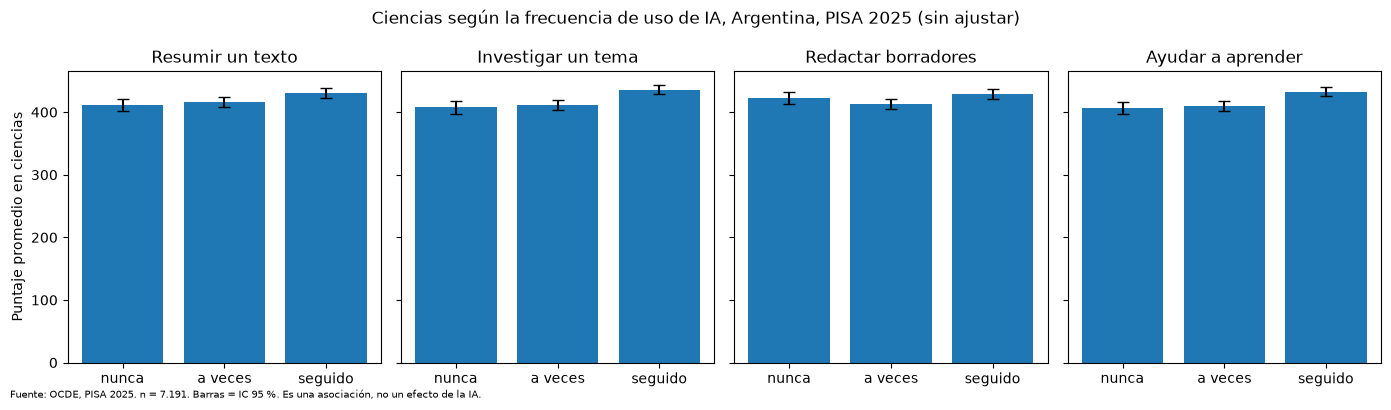

In [13]:
# Figura: ciencias promedio según la frecuencia de uso, por actividad
fig, ejes = plt.subplots(1, 4, figsize=(14, 4), sharey=True)
numero = 0
for pregunta in actividades:
    medias = []
    errores = []
    for grupo_frecuencia in ["nunca", "a_veces", "seguido"]:
        grupo = muestra_ia[muestra_ia[pregunta + "_grupo"] == grupo_frecuencia]
        media, error = estimar(grupo, media_pv, pv_ciencias)
        medias.append(media[0])
        errores.append(1.96 * error[0])
    ejes[numero].bar([0, 1, 2], medias, yerr=errores, capsize=4)
    ejes[numero].set_xticks([0, 1, 2])
    ejes[numero].set_xticklabels(["nunca", "a veces", "seguido"])
    ejes[numero].set_title(actividades[pregunta])
    numero = numero + 1

ejes[0].set_ylabel("Puntaje promedio en ciencias")
fig.suptitle("Ciencias según la frecuencia de uso de IA, Argentina, PISA 2025 (sin ajustar)")
fig.text(0.01, 0.01, "Fuente: OCDE, PISA 2025. n = 7.191. Barras = IC 95 %. Es una asociación, no un efecto de la IA.", fontsize=7)
fig.tight_layout()
fig.savefig(carpeta_figuras / "03_ciencias_por_frecuencia_ia.png", dpi=120)
plt.show()

**Lectura de H3.** Quienes usan IA *seguido* tienen mayor puntaje en ciencias que quienes *nunca* la usan en tres de las cuatro actividades: investigar un tema (+28,4 puntos; IC 95 %: 17,6 a 39,3), ayudar a aprender (+26,6; 17,2 a 36,0) y resumir un texto (+18,8; 9,4 a 28,1). Esas tres siguen siendo significativas con la corrección de Bonferroni. Para redactar borradores el resultado no es concluyente (+7,1; -3,0 a 17,2: el intervalo es amplio e incluye el cero). Para usar IA *a veces* no hay evidencia suficiente de diferencia con no usarla en ninguna actividad (en redactar borradores da -8,5; -18,0 a 0,9). Todo vale para quienes contestaron las cuatro preguntas. **Veredicto: evidencia compatible con una asociación** para uso frecuente en tres actividades; evidencia insuficiente en el resto. Estas diferencias no están ajustadas por contexto.

## 6. H4 · Asociación entre uso de IA y rendimiento tras ajustar

**H0:** no hay asociación entre el uso de IA y el rendimiento una vez ajustado por el contexto. Modelo: puntaje de ciencias explicado por la frecuencia de IA (promedio de las cuatro preguntas), ESCS, sexo (`MALE`) y grado respecto del modal. Se eligen estos controles antes de ver los resultados y son características del estudiante anteriores al uso de IA o independientes de él. Además se ajusta un modelo por actividad.

In [14]:
controles = ["ESCS", "MALE", "GRADE"]

coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["ia_promedio"] + controles)
guardar("H4", "Coeficiente de la frecuencia de IA (promedio 1 a 5), ajustado (puntos por punto de frecuencia)",
        len(muestra_ia), coeficientes[1], errores[1])

# El mismo modelo sin ajustar, para ver cuánto cambia
coeficientes_sin, errores_sin = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=["ia_promedio"])
guardar("H4", "Coeficiente de la frecuencia de IA (promedio 1 a 5), sin ajustar",
        len(muestra_ia), coeficientes_sin[1], errores_sin[1])

for pregunta in actividades:
    coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=[pregunta] + controles)
    guardar("H4", actividades[pregunta] + ": coeficiente ajustado (puntos por punto de frecuencia)",
            len(muestra_ia), coeficientes[1], errores[1])

tabla_h4 = pd.DataFrame(resultados)
tabla_h4 = tabla_h4[tabla_h4["hipotesis"] == "H4"]
print(tabla_h4[["parametro", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]].to_string())

                                                                                         parametro  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto                      veredicto
17  Coeficiente de la frecuencia de IA (promedio 1 a 5), ajustado (puntos por punto de frecuencia)       4.027           1.474          1.138          6.916   0.0063  compatible con una asociación
18                                Coeficiente de la frecuencia de IA (promedio 1 a 5), sin ajustar       9.477           1.652          6.239         12.716  <0,0001  compatible con una asociación
19                         Resumir un texto: coeficiente ajustado (puntos por punto de frecuencia)       1.595           1.144         -0.648          3.838   0.1634         evidencia insuficiente
20                       Investigar un tema: coeficiente ajustado (puntos por punto de frecuencia)       5.244           1.346          2.606          7.882  <0,0001  compatible con una asociación
21             

**Lectura de H4.** Al ajustar por ESCS, sexo y grado, la asociación entre frecuencia de uso de IA y ciencias baja de 9,5 a 4,0 puntos por punto de frecuencia (IC 95 %: 1,1 a 6,9), es decir, a menos de la mitad, pero no desaparece. Por actividad, persiste para investigar un tema (5,2) y ayudar a aprender (5,5); para resumir (1,6) y redactar borradores (-0,6) la evidencia es insuficiente. **Veredicto: evidencia compatible con una asociación condicional**, de magnitud modesta. Al ajustar, la asociación se reduce a menos de la mitad, lo que indica que buena parte de la diferencia inicial va junto con el contexto socioeconómico. Los resultados valen para quienes contestaron las preguntas de IA. No se descarta que influyan otras variables que no tenemos, ni que quienes rinden más usen más la IA y no al revés.

## 7. H5 (exploratoria) · ¿Cambia la asociación según el ESCS?

**H0:** la asociación entre IA y rendimiento no varía con el ESCS. Parámetro: coeficiente de la interacción entre la frecuencia de IA y el ESCS (ambos centrados), en el mismo modelo ajustado. Es una hipótesis exploratoria: se informa sin corrección y no se saca ninguna conclusión fuerte de ella.

In [15]:
predictores_h5 = ["ia_centrado", "escs_centrado", "ia_por_escs", "MALE", "GRADE"]
coeficientes, errores = estimar(muestra_ia, regresion_pv, pv_ciencias, predictores=predictores_h5)

guardar("H5", "Interacción frecuencia de IA × ESCS (puntos)", len(muestra_ia), coeficientes[3], errores[3],
        nota="exploratoria")
guardar("H5", "Coeficiente de IA con ESCS promedio (modelo con interacción)", len(muestra_ia), coeficientes[1], errores[1],
        nota="exploratoria")

tabla_h5 = pd.DataFrame(resultados)
tabla_h5 = tabla_h5[tabla_h5["hipotesis"] == "H5"]
print(tabla_h5[["parametro", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]].to_string())

                                                       parametro  estimacion  error_estandar  ic95_inferior  ic95_superior p_texto                      veredicto
23                  Interacción frecuencia de IA × ESCS (puntos)       2.422           1.392         -0.306          5.150  0.0818         evidencia insuficiente
24  Coeficiente de IA con ESCS promedio (modelo con interacción)       4.359           1.448          1.520          7.197  0.0026  compatible con una asociación


**Lectura de H5.** La interacción es de +2,4 puntos (IC 95 %: -0,3 a 5,2): sugiere que la asociación podría ser algo mayor entre estudiantes de mayor ESCS, pero el intervalo incluye el cero. **Veredicto: evidencia insuficiente.** Es exploratoria y no se saca una conclusión de ella.

## 8. Hipótesis complementaria HC1 (exploratoria) · Quienes no contestaron las preguntas de IA

En la preparación de datos (notebook 02) apareció algo llamativo que no estaba en el plan: los estudiantes que no contestaron las cuatro preguntas de IA parecían rendir menos y tener menor ESCS. Se prueba como hipótesis complementaria, **separada de H1 a H5**.

**H0 (HC1):** el rendimiento de quienes contestaron las cuatro preguntas de IA no difiere del de quienes no las contestaron. Parámetro: diferencia de puntaje en ciencias, sin ajustar y ajustada por ESCS. Se excluyen los 526 estudiantes a quienes la pregunta no se administró (código 97), porque no es una no respuesta.

In [16]:
datos["contesto_ia"] = (datos["ia_estado"] == "respondio_las_4").astype(int)

# Se sacan los 526 estudiantes a quienes la pregunta no se administró (no es lo mismo que no contestar)
datos_hc1 = datos[~datos["ia_no_administrado"]].copy()
print("Estudiantes en HC1 (sin los de pregunta no administrada):", len(datos_hc1))
print("Contestaron las 4:", datos_hc1["contesto_ia"].sum(), "| No contestaron las 4:", (datos_hc1["contesto_ia"] == 0).sum())

estimacion, error = estimar(datos_hc1, diferencia_pv, pv_ciencias, columna="contesto_ia", grupo_a=1, grupo_b=0)
guardar("HC1", "Ciencias: contestó IA menos no contestó (puntos), sin ajustar", len(datos_hc1), estimacion[0], error[0],
        nota="exploratoria")

datos_hc1_con_escs = datos_hc1[datos_hc1["ESCS"].notna()].copy()
coeficientes, errores = estimar(datos_hc1_con_escs, regresion_pv, pv_ciencias, predictores=["contesto_ia", "ESCS"])
guardar("HC1", "Ciencias: contestó IA menos no contestó (puntos), ajustado por ESCS", len(datos_hc1_con_escs),
        coeficientes[1], errores[1], nota="exploratoria")

tabla_hc1 = pd.DataFrame(resultados)
tabla_hc1 = tabla_hc1[tabla_hc1["hipotesis"] == "HC1"]
print(tabla_hc1[["parametro", "n", "estimacion", "error_estandar", "ic95_inferior", "ic95_superior", "p_texto", "veredicto"]].to_string())

Estudiantes en HC1 (sin los de pregunta no administrada): 10566
Contestaron las 4: 7475 | No contestaron las 4: 3091


                                                              parametro      n  estimacion  error_estandar  ic95_inferior  ic95_superior  p_texto                      veredicto
25        Ciencias: contestó IA menos no contestó (puntos), sin ajustar  10566      65.960           4.205         57.718         74.202  <0,0001  compatible con una asociación
26  Ciencias: contestó IA menos no contestó (puntos), ajustado por ESCS   9808      53.802           3.794         46.365         61.240  <0,0001  compatible con una asociación


**Lectura de HC1.** Los estudiantes que contestaron las cuatro preguntas de IA tienen 66,0 puntos más de ciencias que los que no las contestaron (IC 95 %: 57,7 a 74,2; n = 10.566, sin los 526 a quienes la pregunta no se administró). Al ajustar por ESCS (n = 9.808) la diferencia baja a 53,8 puntos (46,4 a 61,2), es decir, sigue siendo grande: no se explica solo por el nivel socioeconómico. **Veredicto: evidencia compatible con una asociación.** Esto importa para todo lo anterior: los resultados sobre el uso de IA (H2 a H5) valen para quienes contestaron, que rinden bastante más que quienes no, y no necesariamente para el conjunto de los estudiantes argentinos.

## 9. Tabla completa de resultados

In [17]:
tabla_final = pd.DataFrame(resultados)
tabla_final.to_csv(carpeta_tablas / "03_resultados_hipotesis.csv", index=False)
print(tabla_final[["hipotesis", "parametro", "n", "estimacion", "error_estandar", "p_texto", "veredicto"]].to_string())

   hipotesis                                                                                                                       parametro      n  estimacion  error_estandar  p_texto                      veredicto
0         H1                                                                       Pendiente de ESCS en Ciencias (puntos por unidad de ESCS)   9808      30.585           2.169  <0,0001  compatible con una asociación
1         H1                                                                     Pendiente de ESCS en Matemática (puntos por unidad de ESCS)   9808      29.290           1.978  <0,0001  compatible con una asociación
2         H1                                                                        Pendiente de ESCS en Lectura (puntos por unidad de ESCS)   9808      28.180           2.030  <0,0001  compatible con una asociación
3         H1                                                                            Ciencias: cuartil 4 de ESCS menos cuartil 1 (pun

## 10. Respuesta a cada hipótesis

| Hipótesis | Respuesta | Resultado principal |
| --- | --- | --- |
| H1 · ESCS y rendimiento | Evidencia compatible con una asociación | +30,6 puntos de ciencias por unidad de ESCS; cuartil 4 menos cuartil 1: 82,4 puntos |
| H2 · IA y ESCS | Evidencia compatible con una asociación | Mayor uso frecuente de IA en el cuartil más alto: entre 13 y 17 puntos porcentuales según la actividad |
| H3 · Rendimiento según uso de IA (sin ajustar) | Compatible con una asociación para uso *seguido* en investigar, ayudar a aprender y resumir; insuficiente en redactar y para uso *a veces* | +18,8 a +28,4 puntos de ciencias |
| H4 · IA y rendimiento ajustando | Compatible con una asociación, de magnitud modesta | +4,0 puntos por punto de frecuencia (sin ajustar: +9,5) |
| H5 · Interacción IA × ESCS (exploratoria) | Evidencia insuficiente | +2,4 (IC 95 %: -0,3 a 5,2) |
| HC1 · No contestar IA y rendimiento (complementaria) | Compatible con una asociación | 66,0 puntos menos de ciencias en quienes no contestaron (53,8 ajustado por ESCS) |

**Límites que condicionan todo.**
- Son asociaciones. No se puede decir que la IA mejore o empeore el rendimiento: también es posible que quienes rinden más usen más la IA.
- El uso de IA es autorreportado y alrededor de un tercio de los estudiantes (32,6 %) no contestó las cuatro preguntas (3.091 no respondieron y 526 no fueron administrados); quienes no respondieron rinden bastante menos (HC1), así que H2 a H5 valen solo para quienes contestaron.
- ESCS es un índice relativo, no un ingreso. Los controles disponibles son pocos (sexo y grado).
- Solo H3 se informa con corrección de Bonferroni (8 comparaciones); en H4 (6 estimaciones) y en las demás tablas se usó p < 0,05 sin corrección, así que los resultados límite deben leerse con cautela.
- Los cuartiles de ESCS se calcularon una vez con el peso final y no se recalcularon con cada peso replicado.
- El factor de Fay (0,5) y la fórmula de varianza siguen sin confirmarse en la documentación técnica de PISA 2025 ni contrastarse con otro software.